# 01 - Data Understanding

This notebook performs an initial inspection of the IBM HR Analytics Employee Attrition dataset.

The objective is to understand the structure of the dataset before performing
any preprocessing or machine learning. In particular, this notebook analyses:

- Dataset dimensions
- Variable types
- Missing values
- Constant variables
- Identifier variables
- Categorical variable values
- Target class distribution
- A summary of the role of each variable

In [59]:
# Import the libraries required for the initial data inspection.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configure pandas so that all columns and up to 100 rows can be displayed.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 1. Dataset Loading

The original dataset is loaded from the `data/raw` directory.

The raw dataset is never modified directly. Any future processed version will
be stored separately in `data/processed`.

In [60]:
# Path to the original dataset.
DATA_PATH = "../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv"

# Load the dataset into a pandas DataFrame.
df = pd.read_csv(DATA_PATH)

## 2. Initial Dataset Inspection

The first step is to inspect several rows and determine the dimensions and
general structure of the dataset.

In [61]:
# Display the first five observations.
display(df.head())

# Display the number of observations and variables.
print(f"Number of observations: {df.shape[0]}")
print(f"Number of variables: {df.shape[1]}")

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Number of observations: 1470
Number of variables: 35


In [62]:
# Show column names, data types, number of non-null values and memory usage.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 3. Descriptive Statistics

Numerical and categorical variables are inspected separately because their
summary statistics have different interpretations.

In [63]:
# Summary statistics for numerical variables.
display(df.describe().T)

# Summary statistics for categorical variables.
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


C:\Users\adolf\AppData\Local\Temp\ipykernel_21572\4144618886.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


## 4. Missing Values

Missing values are checked before preprocessing. Their presence would determine
whether imputation or removal strategies are required.

In [64]:
# Count missing values in each variable.
missing_values = df.isnull().sum()

# Display only variables containing missing values.
missing_variables = missing_values[missing_values > 0].sort_values(
    ascending=False
)

if len(missing_variables) == 0:
    print("No missing values were found in the dataset.")
else:
    display(missing_variables)

print(f"\nTotal missing values: {missing_values.sum()}")

No missing values were found in the dataset.

Total missing values: 0


## 5. Unique and Constant Values

The number of unique values is useful for identifying constant attributes,
binary variables, categorical variables and possible identifier columns.

Constant attributes do not provide information to a classifier and should
therefore be removed during preprocessing.

In [65]:
# Count the number of distinct values in every variable.
unique_values = df.nunique().sort_values()

display(unique_values)

# Identify variables that contain only one unique value.
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("\nConstant variables:")
print(constant_columns)

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate


Constant variables:
['EmployeeCount', 'Over18', 'StandardHours']


## 6. Identifier Variables

Identifier variables uniquely identify observations but usually do not contain
generalizable information about the phenomenon being predicted.

`EmployeeNumber` is inspected to determine whether it behaves as a unique
identifier.

In [66]:
# Compare the number of unique employee identifiers with the number of rows.
employee_ids = df["EmployeeNumber"].nunique()
number_of_rows = df.shape[0]

print(f"Unique EmployeeNumber values: {employee_ids}")
print(f"Number of observations: {number_of_rows}")

if employee_ids == number_of_rows:
    print("EmployeeNumber uniquely identifies each observation.")

Unique EmployeeNumber values: 1470
Number of observations: 1470
EmployeeNumber uniquely identifies each observation.


## 7. Numerical and Categorical Variables

The predictors are separated according to their data type. This distinction
will later determine the preprocessing operations applied to each group.

Numerical variables may require scaling for some classifiers, whereas
categorical variables may require encoding.

In [67]:
# Identify numerical variables.
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Identify non-numerical (categorical) variables.
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print(f"Number of numerical variables: {len(numeric_columns)}")
print(numeric_columns)

print(f"\nNumber of categorical variables: {len(categorical_columns)}")
print(categorical_columns)

Number of numerical variables: 26
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Number of categorical variables: 9
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


## 8. Categorical Variable Inspection

The categories and their frequencies are inspected to understand the possible
values of each categorical attribute and to detect unusual or inconsistent
categories.

In [68]:
# Display the frequency of each category for every categorical variable.
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Attrition ---
Attrition
No     1233
Yes     237
Name: count, dtype: int64

--- BusinessTravel ---
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

--- Department ---
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

--- EducationField ---
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

--- Gender ---
Gender
Male      882
Female    588
Name: count, dtype: int64

--- JobRole ---
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int

## 9. Target Variable Distribution

`Attrition` is the target variable of the classification problem.

Its distribution is analysed because a strong imbalance between the two
classes can make accuracy misleading and may require the use of additional
evaluation metrics such as precision, recall, F1-score and balanced accuracy.

In [69]:
# Absolute number of observations in each class.
target_counts = df["Attrition"].value_counts()

# Percentage of observations in each class.
target_percentages = (
    df["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

,Count,Percentage
Attrition,,
No,1233,83.88
Yes,237,16.12


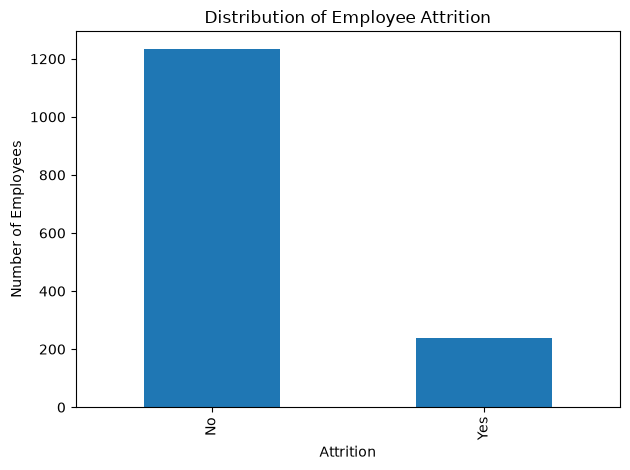

In [70]:
# Visualize the distribution of the target variable.
df["Attrition"].value_counts().plot(kind="bar")

plt.title("Distribution of Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()

# Save the figure for later use in the LaTeX report.
plt.savefig(
    "../figures/attrition_distribution.pdf",
    bbox_inches="tight"
)

plt.show()

## 10. Variable Summary

A summary table is created to document the characteristics and role of every
variable in the dataset.

Each attribute is classified as one of the following:

- **Target:** variable to be predicted.
- **Predictor:** candidate input variable.
- **Identifier:** uniquely identifies an observation and should not be used for prediction.
- **Constant:** contains no variability and therefore provides no predictive information.

In [71]:
# Create a summary describing every variable in the dataset.
variable_summary = pd.DataFrame({
    "Variable": df.columns,
    "DataType": df.dtypes.astype(str).values,
    "UniqueValues": df.nunique().values,
    "MissingValues": df.isnull().sum().values
})

# Initially consider every variable to be a predictor.
variable_summary["Role"] = "Predictor"

# Mark the classification target.
variable_summary.loc[
    variable_summary["Variable"] == "Attrition",
    "Role"
] = "Target"

# Mark the employee identifier.
variable_summary.loc[
    variable_summary["Variable"] == "EmployeeNumber",
    "Role"
] = "Identifier"

# Mark constant variables.
variable_summary.loc[
    variable_summary["Variable"].isin(constant_columns),
    "Role"
] = "Constant"

display(variable_summary)

,Variable,DataType,UniqueValues,MissingValues,Role
0,Age,int64,43,0,Predictor
1,Attrition,str,2,0,Target
2,BusinessTravel,str,3,0,Predictor
3,DailyRate,int64,886,0,Predictor
4,Department,str,3,0,Predictor
5,DistanceFromHome,int64,29,0,Predictor
6,Education,int64,5,0,Predictor
7,EducationField,str,6,0,Predictor
8,EmployeeCount,int64,1,0,Constant
9,EmployeeNumber,int64,1470,0,Identifier


In [72]:
# Export the variable summary so that it can be reused in later stages.
variable_summary.to_csv(
    "../results/variable_summary.csv",
    index=False
)

print("Variable summary saved successfully.")

Variable summary saved successfully.
